In [1]:
from common import *

## Density maps

In [10]:
alignments = ['global', 'local']
path = PROJECT_DIR / "density"

data = []
for align in alignments:
    for filename in path.glob(f"*/{align}/all/replicate?_rep??.pkl"):
        weight_file = filename.with_stem(filename.stem + "_weight").with_suffix(".txt")
        if weight_file.exists():
            with open(weight_file, "r") as f:
                weight = float(f.read())
        else:
            weight = 1

        map_ = SparseGrid.load(filename)

        data.append(
            dict(
                sim=filename.parent.parent.parent.name,
                align=align,
                block=filename.stem,
                filename=str(filename),
                map=map_,
                weight=weight,
            )
        )

In [11]:
gen_maps = pd.DataFrame(data)
gen_maps["weight"] /= gen_maps.groupby(["sim", "align"])["weight"].transform("sum")
gen_map_avg = gen_maps.groupby(['sim', 'align'])[['map', 'weight']].apply(lambda x: np.average(x['map'], weights=x['weight']))

ref_map_sharpened = Grid(PROJECT_DIR / "density/emd_42499.mrc")
ref_maps = np.array([Grid(PROJECT_DIR / "density/emd_42499_Con2-2.2A_half_A.mrc"), Grid(PROJECT_DIR / "density/emd_42499_Con2-2.2A_half_B.mrc")])
ref_map = np.mean(ref_maps)
rna = mda.Universe(PROJECT_DIR / "structures/9CBU_fixed.pdb").select_atoms("nucleic and not type H and not (resid 22 and name P OP1 OP2)")
core = rna.select_atoms('not resid 63:88 229:245 284:295 332:335 364:402')

masks = {
    'All': indices_to_mask(voxels_around(rna, 6, ref_map.grid_params), ref_map.grid_params),
    'Core': indices_to_mask(voxels_around(core, 6, ref_map.grid_params), ref_map.grid_params),
    'Core Phosphates': indices_to_mask(voxels_around(core.select_atoms('name P'), 6, ref_map.grid_params), ref_map.grid_params),
}

masks['All (Shell only)'] = masks['All'] & ~indices_to_mask(voxels_around(rna, 1.8, ref_map.grid_params), ref_map.grid_params)
masks['Core (Shell only)'] = masks['Core'] & masks['All (Shell only)']
masks['Core Phosphates (Shell only)'] = masks['Core Phosphates'] & masks['All (Shell only)']

/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:479: UserWarning: 1 A^3 CRYST1 record, this is usually a placeholder. Unit cell dimensions will be set to None.
  warnings.warn(


In [12]:
# Save ref map for later use
ref_map.astype(np.float32).export('ref_map.mrc')

In [13]:
gen_map_avg.loc['replex_7ez0_mMg_tip3p', 'global'].to_dense().astype(np.float32).export('replex_7ez0_mMg_tip3p_global.mrc')

In [14]:
# For figure
from mg_sampling.parallel import ParallelReader
ref = mda.Universe(PROJECT_DIR / 'structures/9CBU_fixed.pdb')
u = mda.Universe(PROJECT_DIR / 'replex/7ez0/mMg_tip3p/replicate0/rep00/input.gro',
                 [PROJECT_DIR / f'replex/7ez0/mMg_tip3p/replicate0/rep0{i}/run.xtc'
                  for i in range(8)],
                 format=ParallelReader)
u.trajectory.demux(PROJECT_DIR / 'replex/7ez0/mMg_tip3p/replicate0/rep00/bias_index.xvg')  # re-muxing
rna = u.select_atoms('nucleic')
phosphates = u.select_atoms('name P and not resid 22')
# Last frame
u.trajectory[-1, 0]
unwrap_sequential(rna)
wrap_around_atomgroup(u.atoms, phosphates)
alignto(phosphates, ref.select_atoms('name P and not resid 22'))


/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:479: UserWarning: 1 A^3 CRYST1 record, this is usually a placeholder. Unit cell dimensions will be set to None.
  warnings.warn(


(np.float64(15.962826936587133), 1.708448458436589)

In [15]:
with mda.Writer('replex_final.pdb', n_atoms=len(u.atoms)) as w:
    w.write(u.atoms)

/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'altLocs' Using default value of ' '
  warnings.warn(
/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'icodes' Using default value of ' '
  warnings.warn(
/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'chainIDs' Using default value of ''
  warnings.warn(
/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'occupancies' Using default value of '1.0'
  warnings.warn(
/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'tem

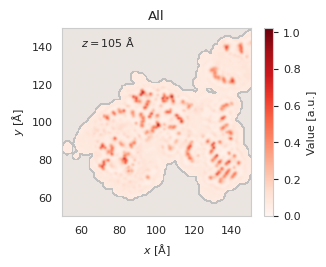

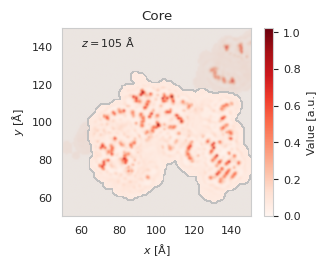

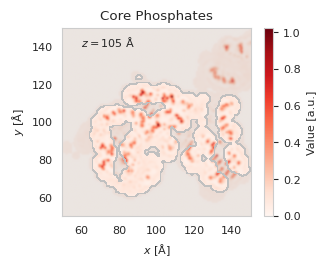

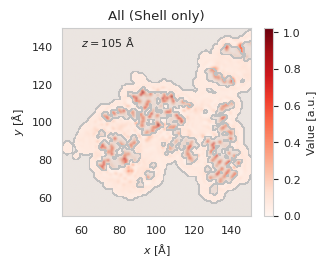

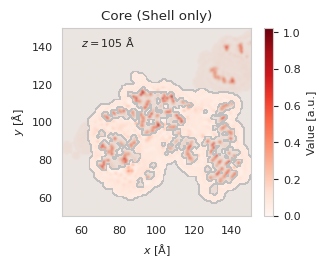

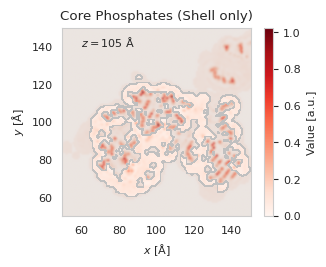

In [16]:

for label, mask in masks.items():
    fig, ax = plt.subplots(figsize=(8.7*cm, 6.5*cm))

    map_ = gen_map_avg.iloc[0].to_dense()

    plt.rcParams['hatch.color'] = 'silver'
    im = plot_map_slice(map_, cmap='Reds', interpolation='bicubic')
    hatches = plot_map_slice(Grid(mask, edges=map_.edges), func='contourf', colors=[('silver', 0.3), 'none'], corner_mask=True)
    hatches.set_edgecolor('silver')
    hatches.set_linewidth(0.5)
    cbar = plt.colorbar(im, ax=ax, fraction=0.05, label='Value [a.u.]')
    ax.set_xlim(50, 150)
    ax.set_ylim(50, 150)
    depth = np.median(map_.edges[-1])
    ax.text(0.1, 0.9, f"$z = {depth:.0f}$ Å", transform=ax.transAxes)
    ax.set_xlabel("$x$ [Å]")
    ax.set_ylabel("$y$ [Å]")
    _label = ''.join(c.lower() for c in label if c.isalnum())
    ax.set_title(label)
    ax.grid(False)
    fig.savefig(f"figures/gen_map_{_label}.pdf")

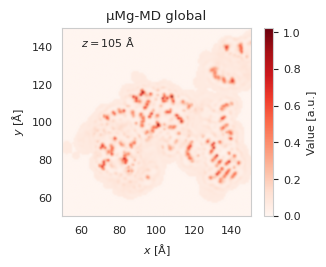

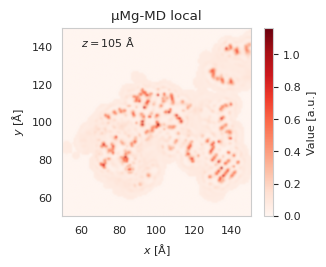

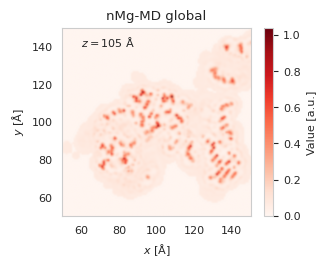

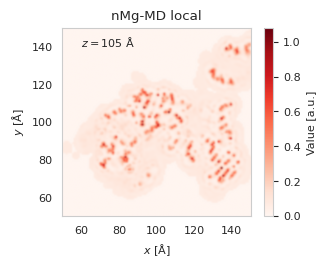

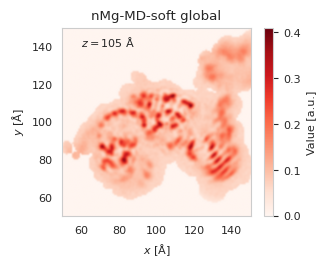

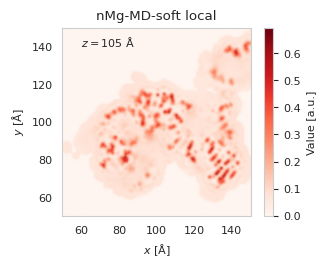

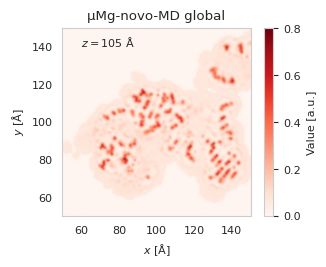

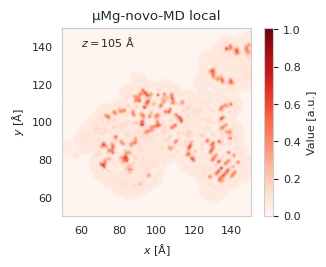

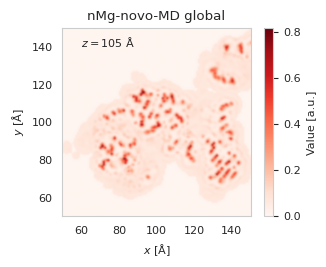

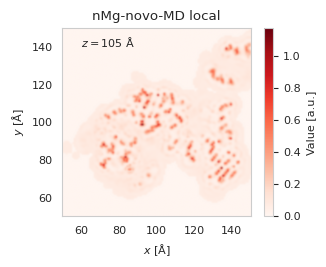

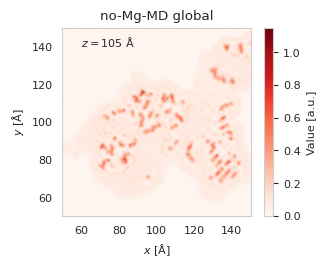

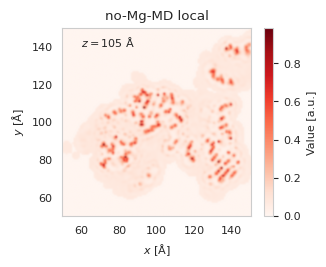

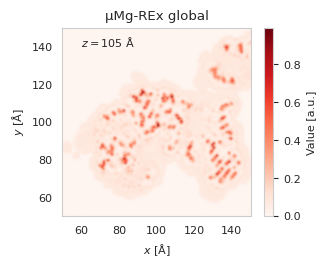

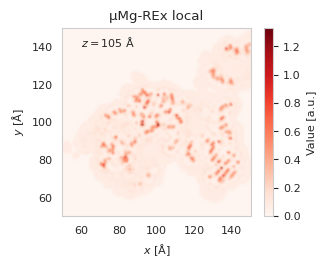

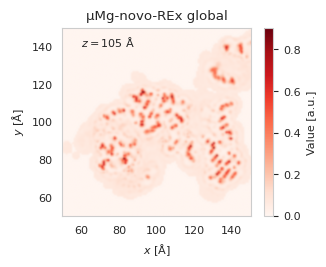

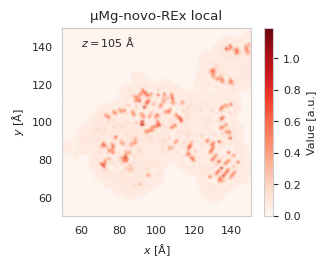

In [17]:
for (sim, align), map_ in gen_map_avg.items():
    fig, ax = plt.subplots(figsize=(8.7*cm, 6.5*cm))

    map_ = map_.to_dense()

    plt.rcParams['hatch.color'] = 'silver'
    im = plot_map_slice(map_, cmap='Reds', interpolation='bicubic')
    #hatches = plot_map_slice(Grid(mask, edges=map_.edges), func='contourf', colors=[('silver', 0.3), 'none'], corner_mask=True)
    #hatches.set_edgecolor('silver')
    #hatches.set_linewidth(0.5)
    cbar = plt.colorbar(im, ax=ax, fraction=0.05, label='Value [a.u.]')
    ax.set_xlim(50, 150)
    ax.set_ylim(50, 150)
    depth = np.median(map_.edges[-1])
    ax.text(0.1, 0.9, f"$z = {depth:.0f}$ Å", transform=ax.transAxes)
    ax.set_xlabel("$x$ [Å]")
    ax.set_ylabel("$y$ [Å]")
    _label = ''.join(c.lower() for c in label if c.isalnum())
    ax.set_title(simlabels[sim] + f" {align}")
    ax.grid(False)
    fig.savefig(f"figures/gen_map_{sim}_{align}.pdf")

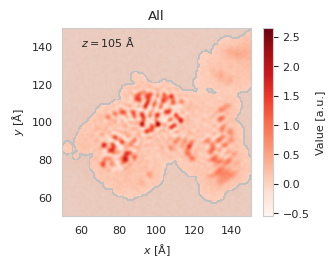

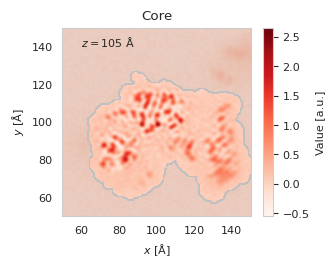

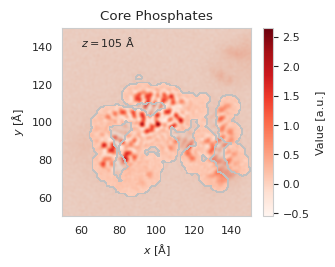

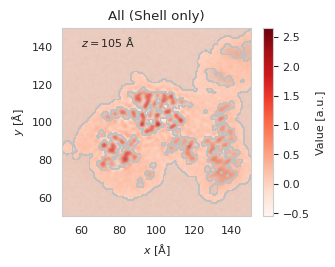

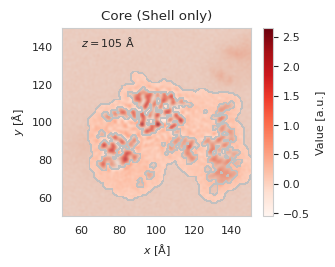

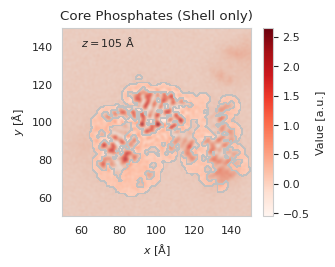

In [18]:
for label, mask in masks.items():
    fig, ax = plt.subplots(figsize=(8.7*cm, 6.5*cm))

    plt.rcParams['hatch.color'] = 'silver'
    im = plot_map_slice(ref_map, cmap='Reds', interpolation='bicubic')
    hatches = plot_map_slice(Grid(mask, edges=ref_map.edges), func='contourf', colors=[('silver', 0.3), 'none'], corner_mask=True)
    hatches.set_edgecolor('silver')
    hatches.set_linewidth(0.5)
    cbar = plt.colorbar(im, ax=ax, fraction=0.05, label='Value [a.u.]')
    ax.set_xlim(50, 150)
    ax.set_ylim(50, 150)
    depth = np.median(ref_map.edges[-1])
    ax.text(0.1, 0.9, f"$z = {depth:.0f}$ Å", transform=ax.transAxes)
    ax.set_xlabel("$x$ [Å]")
    ax.set_ylabel("$y$ [Å]")
    _label = ''.join(c.lower() for c in label if c.isalnum())
    ax.set_title(label)
    ax.grid(False)
    fig.savefig(f"figures/ref_map_{_label}.pdf")

### Determine best B-Factor

#### Unsharpened maps

In [42]:
tempfactors = np.linspace(0, 100, 10+1)

if compute:
    ref_map = 0.5 * (Grid(PROJECT_DIR / "density/emd_42499_Con2-2.2A_half_A.mrc") + Grid(PROJECT_DIR / "density/emd_42499_Con2-2.2A_half_B.mrc"))
    rna = mda.Universe(PROJECT_DIR / "structures/9CBU_fixed.pdb").select_atoms("nucleic and not type H and not (resid 22 and name P OP1 OP2)")    
    
    def get_cc(map_, tempfactor, cc_mask):
        return linregress(map_.apply_tempfactor(tempfactor).grid[cc_mask], ref_map.grid[cc_mask]).rvalue
    
    results = {
        (*label, m): [get_cc(map_.to_dense(), tempfactor, masks[m]) for tempfactor in tqdm(tempfactors)]
        for label, map_ in gen_map_avg.items()
        for m in ['All', 'Core Phosphates (Shell only)']
    }
    results = pd.DataFrame(results).transpose()
    results.to_parquet('tempfactor_scan.parquet')
else:
    results = pd.read_parquet('tempfactor_scan.parquet')
results.head()

/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:479: UserWarning: 1 A^3 CRYST1 record, this is usually a placeholder. Unit cell dimensions will be set to None.
  warnings.warn(
100%|██████████| 11/11 [00:22<00:00,  2.04s/it]


0   \
plain_md_7ez0_mMg_tip3p global All                           0.648513   
                               Core Phosphates (Shell only)  0.329587   
                        local  All                           0.711559   
                               Core Phosphates (Shell only)  0.378058   
plain_md_7ez0_nMg_tip3p global All                           0.651837   

                                                                   1   \
plain_md_7ez0_mMg_tip3p global All                           0.691323   
                               Core Phosphates (Shell only)  0.336914   
                        local  All                           0.764244   
                               Core Phosphates (Shell only)  0.402276   
plain_md_7ez0_nMg_tip3p global All                           0.694595   

                                                                   2   \
plain_md_7ez0_mMg_tip3p global All                           0.708268   
                               Core Phosphates (Shell only)  0.321031   
                        local  All                           0.780368   
                               Core Phosphates (Shell only)  0.396163   
plain_md_7ez0_nMg_tip3p global All                           0.711298   

                                                                   3   \
plain_md_7ez0_mMg_tip3p global All                           0.713321   
                               Core Phosphates (Shell only)  0.292902   
                        local  All                           0.781271   
                               Core Phosphates (Shell only)  0.366962   
plain_md_7ez0_nMg_tip3p global All                           0.716052   

                                                                   4   \
plain_md_7ez0_mMg_tip3p global All                           0.711722   
                               Core Phosphates (Shell only)  0.260135   
                        local  All                           0.774443   
                               Core Phosphates (Shell only)  0.324402   
plain_md_7ez0_nMg_tip3p global All                           0.714146   

                                                                   5   \
plain_md_7ez0_mMg_tip3p global All                           0.706137   
                               Core Phosphates (Shell only)  0.227709   
                        local  All                           0.763446   
                               Core Phosphates (Shell only)  0.278496   
plain_md_7ez0_nMg_tip3p global All                           0.708268   

                                                                   6   \
plain_md_7ez0_mMg_tip3p global All                           0.698183   
                               Core Phosphates (Shell only)  0.198280   
                        local  All                           0.750311   
                               Core Phosphates (Shell only)  0.235863   
plain_md_7ez0_nMg_tip3p global All                           0.700049   

                                                                   7   \
plain_md_7ez0_mMg_tip3p global All                           0.688923   
                               Core Phosphates (Shell only)  0.172872   
                        local  All                           0.736283   
                               Core Phosphates (Shell only)  0.199341   
plain_md_7ez0_nMg_tip3p global All                           0.690556   

                                                                   8   \
plain_md_7ez0_mMg_tip3p global All                           0.679070   
                               Core Phosphates (Shell only)  0.151584   
                        local  All                           0.722140   
                               Core Phosphates (Shell only)  0.169380   
plain_md_7ez0_nMg_tip3p global All                           0.680499   

                                                                   9   \
plain_md_7ez0_mMg_tip3p global All         

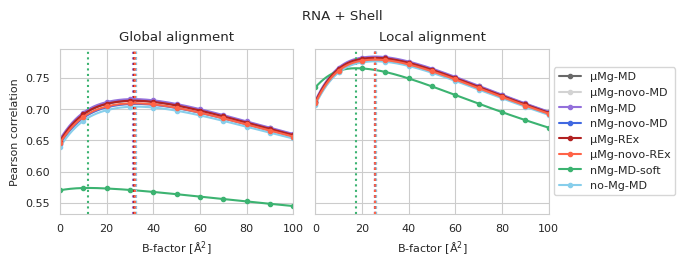

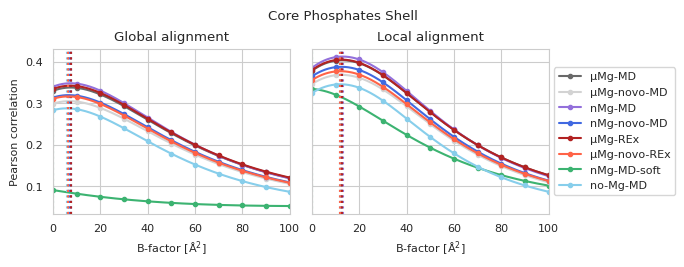

In [44]:
best_tempfactor = {}

for mask in ['All', 'Core Phosphates (Shell only)']:
    fig, axarr = plt.subplots(ncols=2, figsize=(17.1*cm, 6.5*cm), sharey=True)

    for align, ax in zip(alignments, axarr):

        tempfactor_range = np.linspace(0, 100, 1001)

        handles, labels = [], []
        for sim, cc in results.loc[:, align, mask, :].iterrows():
            marks, = ax.plot(tempfactors, cc, marker='.', ls='none', color=simcolors[sim])
            f = interp1d(tempfactors, cc, kind='cubic')
            cc_interp = f(tempfactor_range)
            line, = ax.plot(tempfactor_range, cc_interp, color=marks.get_color())
            handles.append((marks, line))
            best_tempfactor[(sim, align, mask)] = tempfactor_range[np.argmax(cc_interp)]
            ax.axvline(best_tempfactor[(sim, align, mask)], color=line.get_color(), ls='dotted')
            labels.append(simlabels[sim])

        #ax.legend(handles, labels, title=None, loc='lower center', bbox_to_anchor=(0.5, 1), ncol=2)

        ax.set_xlim(0, 100)
        ax.set_xlabel("B-factor [Å$^2$]")
        ax.set_title(align.capitalize() + " alignment")

    axarr[0].set_ylabel("Pearson correlation")

    

    order = [labels.index(label) for label in labelselection]
    labels = [labels[i] for i in order]
    handles = [handles[i] for i in order]
    ax.legend(handles, labels, title=None, loc='center left', bbox_to_anchor=(1, 0.5))
    if mask == 'All':
        title = 'RNA + Shell'
    elif mask == 'Core Phosphates (Shell only)':
        title = 'Core Phosphates Shell'
    else:
        title = mask
    fig.suptitle(title)
    suffix = "".join([c for c in title if c.isalnum()])
    fig.savefig(f'figures/tempfactor_scan_{suffix}.pdf')

In [45]:
best_tempfactors = pd.Series(best_tempfactor)
best_tempfactors.to_csv('best_tempfactors.csv')

In [46]:
best_tempfactors

plain_md_7ez0_mMg_tip3p        global  All                             31.9
plain_md_7ez0_nMg_tip3p        global  All                             31.4
plain_md_7ez0_nMg_tip3p_soft   global  All                             12.2
plain_md_7ez0_noion_mMg_tip3p  global  All                             32.5
plain_md_7ez0_noion_nMg_tip3p  global  All                             32.5
plain_md_7ez0_nomg_mMg_tip3p   global  All                             32.7
replex_7ez0_mMg_tip3p          global  All                             31.6
replex_7ez0_noion_mMg_tip3p    global  All                             32.0
plain_md_7ez0_mMg_tip3p        local   All                             25.8
plain_md_7ez0_nMg_tip3p        local   All                             25.5
plain_md_7ez0_nMg_tip3p_soft   local   All                             17.4
plain_md_7ez0_noion_mMg_tip3p  local   All                             26.0
plain_md_7ez0_noion_nMg_tip3p  local   All                             25.7
plain_md_7ez

#### Sharpened map

In [56]:
tempfactors = np.linspace(0, 100, 10+1)

if compute:
    ref_map_sharpened = Grid(PROJECT_DIR / "density/emd_42499.mrc")
    rna = mda.Universe(PROJECT_DIR / "structures/9CBU_fixed.pdb").select_atoms("nucleic and not type H and not (resid 22 and name P OP1 OP2)")    
    
    def get_cc(map_, tempfactor, cc_mask):
        return linregress(map_.apply_tempfactor(tempfactor).grid[cc_mask], ref_map_sharpened.grid[cc_mask]).rvalue
    
    results = {
        (*label, m): [get_cc(map_.to_dense(), tempfactor, masks[m]) for tempfactor in tqdm(tempfactors)]
        for label, map_ in gen_map_avg.items()
        for m in ['All', 'Core Phosphates (Shell only)']
    }
    results = pd.DataFrame(results).transpose()
    results.to_parquet('tempfactor_scan_sharpened.parquet')
else:
    results = pd.read_parquet('tempfactor_scan_sharpened.parquet')
results.head()

/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:479: UserWarning: 1 A^3 CRYST1 record, this is usually a placeholder. Unit cell dimensions will be set to None.
  warnings.warn(
100%|██████████| 11/11 [00:21<00:00,  1.99s/it]


0   \
plain_md_7ez0_mMg_tip3p global All                           0.437682   
                               Core Phosphates (Shell only)  0.194803   
                        local  All                           0.523982   
                               Core Phosphates (Shell only)  0.306305   
plain_md_7ez0_nMg_tip3p global All                           0.440400   

                                                                   1   \
plain_md_7ez0_mMg_tip3p global All                           0.432252   
                               Core Phosphates (Shell only)  0.142762   
                        local  All                           0.519904   
                               Core Phosphates (Shell only)  0.264867   
plain_md_7ez0_nMg_tip3p global All                           0.434765   

                                                                   2   \
plain_md_7ez0_mMg_tip3p global All                           0.411722   
                               Core Phosphates (Shell only)  0.074432   
                        local  All                           0.491657   
                               Core Phosphates (Shell only)  0.186788   
plain_md_7ez0_nMg_tip3p global All                           0.413924   

                                                                   3   \
plain_md_7ez0_mMg_tip3p global All                           0.386675   
                               Core Phosphates (Shell only)  0.005070   
                        local  All                           0.456903   
                               Core Phosphates (Shell only)  0.092890   
plain_md_7ez0_nMg_tip3p global All                           0.388562   

                                                                   4   \
plain_md_7ez0_mMg_tip3p global All                           0.360925   
                               Core Phosphates (Shell only) -0.056847   
                        local  All                           0.421547   
                               Core Phosphates (Shell only)  0.001829   
plain_md_7ez0_nMg_tip3p global All                           0.362527   

                                                                   5   \
plain_md_7ez0_mMg_tip3p global All                           0.336187   
                               Core Phosphates (Shell only) -0.107942   
                        local  All                           0.388038   
                               Core Phosphates (Shell only) -0.075071   
plain_md_7ez0_nMg_tip3p global All                           0.337541   

                                                                   6   \
plain_md_7ez0_mMg_tip3p global All                           0.313271   
                               Core Phosphates (Shell only) -0.148060   
                        local  All                           0.357431   
                               Core Phosphates (Shell only) -0.134615   
plain_md_7ez0_nMg_tip3p global All                           0.314416   

                                                                   7   \
plain_md_7ez0_mMg_tip3p global All                           0.292516   
                               Core Phosphates (Shell only) -0.178557   
                        local  All                           0.330084   
                               Core Phosphates (Shell only) -0.178401   
plain_md_7ez0_nMg_tip3p global All                           0.293487   

                                                                   8   \
plain_md_7ez0_mMg_tip3p global All                           0.273992   
                               Core Phosphates (Shell only) -0.201223   
                        local  All                           0.305991   
                               Core Phosphates (Shell only) -0.209607   
plain_md_7ez0_nMg_tip3p global All                           0.274820   

                                                                   9   \
plain_md_7ez0_mMg_tip3p global All         

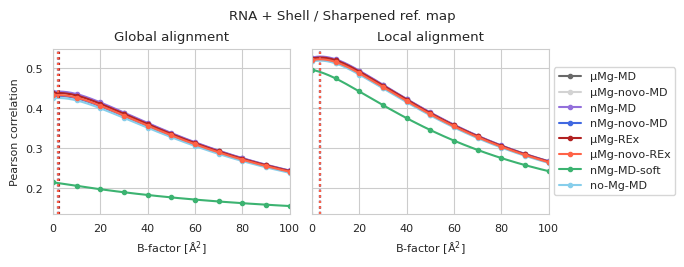

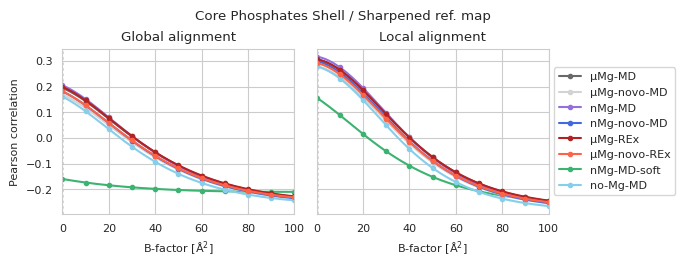

In [57]:
best_tempfactor_sharpened = {}

for mask in ['All', 'Core Phosphates (Shell only)']:
    fig, axarr = plt.subplots(ncols=2, figsize=(17.1*cm, 6.5*cm), sharey=True)

    for align, ax in zip(alignments, axarr):

        tempfactor_range = np.linspace(0, 100, 1001)

        handles, labels = [], []
        for sim, cc in results.loc[:, align, mask, :].iterrows():
            marks, = ax.plot(tempfactors, cc, marker='.', ls='none', color=simcolors[sim])
            f = interp1d(tempfactors, cc, kind='cubic')
            cc_interp = f(tempfactor_range)
            line, = ax.plot(tempfactor_range, cc_interp, color=marks.get_color())
            handles.append((marks, line))
            best_tempfactor_sharpened[(sim, align, mask)] = tempfactor_range[np.argmax(cc_interp)]
            ax.axvline(best_tempfactor_sharpened[(sim, align, mask)], color=line.get_color(), ls='dotted')
            labels.append(simlabels[sim])

        #ax.legend(handles, labels, title=None, loc='lower center', bbox_to_anchor=(0.5, 1), ncol=2)

        ax.set_xlim(0, 100)
        ax.set_xlabel("B-factor [Å$^2$]")
        ax.set_title(align.capitalize() + " alignment")

    axarr[0].set_ylabel("Pearson correlation")

    

    order = [labels.index(label) for label in labelselection]
    labels = [labels[i] for i in order]
    handles = [handles[i] for i in order]
    ax.legend(handles, labels, title=None, loc='center left', bbox_to_anchor=(1, 0.5))
    if mask == 'All':
        title = 'RNA + Shell'
    elif mask == 'Core Phosphates (Shell only)':
        title = 'Core Phosphates Shell'
    else:
        title = mask
    fig.suptitle(title + " / Sharpened ref. map")
    suffix = "".join([c for c in title if c.isalnum()])
    fig.savefig(f'figures/tempfactor_scan_sharpened_{suffix}.pdf')

In [58]:
best_tempfactors_sharpened = pd.Series(best_tempfactor_sharpened)
best_tempfactors_sharpened.to_csv('best_tempfactors_sharpened.csv')

In [59]:
best_tempfactors_sharpened

plain_md_7ez0_mMg_tip3p        global  All                             2.4
plain_md_7ez0_nMg_tip3p        global  All                             2.3
plain_md_7ez0_nMg_tip3p_soft   global  All                             0.0
plain_md_7ez0_noion_mMg_tip3p  global  All                             2.1
plain_md_7ez0_noion_nMg_tip3p  global  All                             2.2
plain_md_7ez0_nomg_mMg_tip3p   global  All                             2.2
replex_7ez0_mMg_tip3p          global  All                             2.4
replex_7ez0_noion_mMg_tip3p    global  All                             2.1
plain_md_7ez0_mMg_tip3p        local   All                             3.6
plain_md_7ez0_nMg_tip3p        local   All                             3.6
plain_md_7ez0_nMg_tip3p_soft   local   All                             0.0
plain_md_7ez0_noion_mMg_tip3p  local   All                             3.5
plain_md_7ez0_noion_nMg_tip3p  local   All                             3.5
plain_md_7ez0_nomg_mMg_ti

In [60]:
best_tempfactors

plain_md_7ez0_mMg_tip3p        global  All                             31.9
plain_md_7ez0_nMg_tip3p        global  All                             31.4
plain_md_7ez0_nMg_tip3p_soft   global  All                             12.2
plain_md_7ez0_noion_mMg_tip3p  global  All                             32.5
plain_md_7ez0_noion_nMg_tip3p  global  All                             32.5
plain_md_7ez0_nomg_mMg_tip3p   global  All                             32.7
replex_7ez0_mMg_tip3p          global  All                             31.6
replex_7ez0_noion_mMg_tip3p    global  All                             32.0
plain_md_7ez0_mMg_tip3p        local   All                             25.8
plain_md_7ez0_nMg_tip3p        local   All                             25.5
plain_md_7ez0_nMg_tip3p_soft   local   All                             17.4
plain_md_7ez0_noion_mMg_tip3p  local   All                             26.0
plain_md_7ez0_noion_nMg_tip3p  local   All                             25.7
plain_md_7ez

### CC

In [16]:
if compute:
    results = []
    
    for m, mask in masks.items():
        for (sim, align), group in tqdm(gen_maps.groupby(["sim", "align"])[["map", "weight"]]):
            ref_data = ref_map.grid[mask]
            def statistic(maps, weights=None):
                return linregress(
                    np.average(maps, weights=weights),
                    ref_data,
                ).rvalue
            best_tempfactor = best_tempfactors.loc[sim, align, m]
            mapsA = group["map"].apply(lambda x: x.to_dense().apply_tempfactor(best_tempfactor).grid[mask]).to_numpy()
            weightsA = group["weight"].to_numpy()
            mapA = np.average(mapsA, weights=weightsA, axis=0)
            cc = linregress(
                mapA,
                ref_data,
            ).rvalue
    
            cc_low, cc_high = bayesian_bootstrap(
                mapsA,
                statistic,
                weights=weightsA,
                n_resamples=200,
                confidence_level=0.99,
            ).confidence_interval
    
            results.append(
                {
                    "sim": sim,
                    "align": align,
                    "mask": m,
                    "cc": cc,
                    "cc_low": cc_low,
                    "cc_high": cc_high,
                }
            )
    res = pd.DataFrame(results)
    res
    res.to_csv('cross_correlations.csv')
else:
    res = pd.read_csv('cross_correlations.csv')

### P-values

In [17]:
if compute:
    df = pd.read_csv('cc_p_values.csv')
    results = []
    for align in alignments:
        for m, mask in masks.items():
            for (simA, groupA), (simB, groupB) in tqdm(itertools.combinations_with_replacement(gen_maps.query("align == @align").groupby("sim")[["map", "weight"]], 2)):
                if not df.query("align == @align and simA == @simA and simB == @simB and mask == @m").empty:
                    print("pass", simA, simB, align, m)
                    continue
                ref_data = ref_map.grid[mask]
                best_tempfactor = best_tempfactors.loc[sim, align, m]

                mapsA = groupA["map"].apply(lambda x: x.to_dense().apply_tempfactor(best_tempfactor).grid[mask]).to_numpy()
                nA = len(mapsA)
                weightsA = groupA["weight"].to_numpy()
                mapsB = groupB["map"].apply(lambda x: x.to_dense().apply_tempfactor(best_tempfactor).grid[mask]).to_numpy()
                nB = len(mapsB)
                weightsB = groupB["weight"].to_numpy()

                def statistic(maps, weights=None):
                    ccA = linregress(
                        np.average(maps[:nA], weights=weights[:nA]),
                        ref_data,
                    ).rvalue
                    ccB = linregress(
                        np.average(maps[nA:], weights=weights[nA:]),
                        ref_data,
                    ).rvalue
                    return float(ccA > ccB)

                p_value = bayesian_bootstrap(
                    np.concatenate([mapsA, mapsB]),
                    statistic,
                    weights=np.concatenate([weightsA, weightsB]),
                    n_resamples=1000,
                ).bootstrap_distribution.mean()

                results.append(
                    {
                        "simA": simA,
                        "simB": simB,
                        "align": align,
                        "mask": m,
                        "p_value": p_value,
                    }
                )
    
    _df = pd.DataFrame(results)
    df = pd.concat([df, _df])
    df.to_csv('cc_p_values.csv')
else:
    df = pd.read_csv('cc_p_values.csv')
p_values = df.set_index(['simA', 'simB', 'align', 'mask']).rename(index=simlabels)

In [18]:
p_values = p_values.groupby(['simA', 'simB', 'align', 'mask'])['p_value'].mean()

In [19]:
for (simA, simB, align, mask) in p_values.index:
    if (simB, simA, align, mask) not in p_values:
        p_values.loc[simB, simA, align, mask] = 1 - p_values.loc[simA, simB, align, mask]

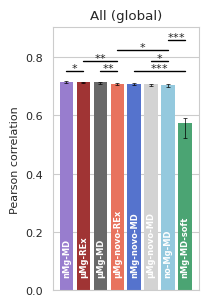

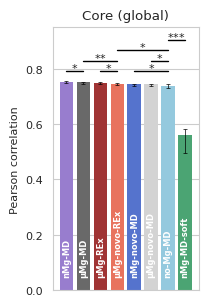

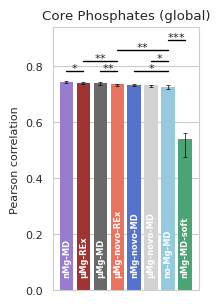

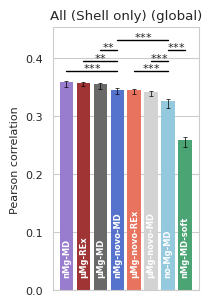

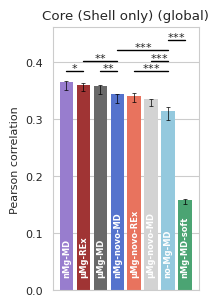

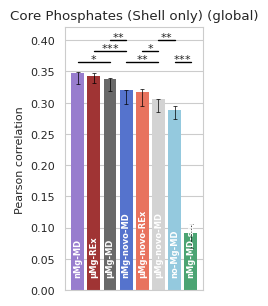

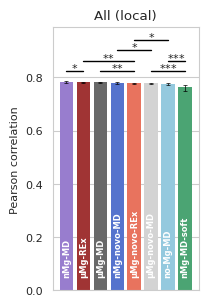

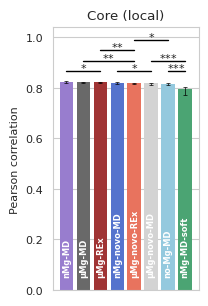

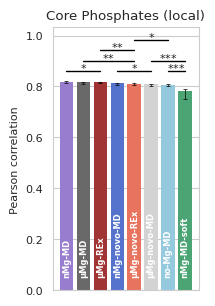

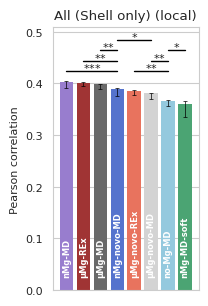

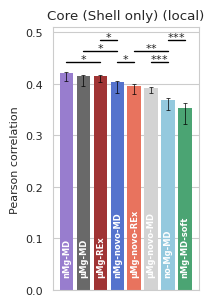

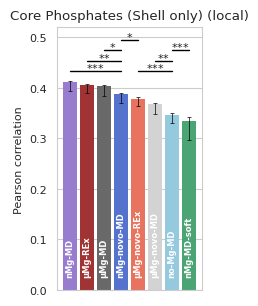

In [20]:
import matplotlib.transforms as transforms
for align in alignments:
    for label in masks.keys():

        group = res.query('mask == @label and align == @align').loc[res['sim'].isin(simselection)]
        group = group.sort_values('cc', ascending=False)
        group['sim'] = group['sim'].map(simlabels)
        group['sim'] = group['sim'].astype(CategoricalDtype(categories=group['sim'], ordered=True))

        fig, ax = plt.subplots(figsize=(5*cm, 7.5*cm))
        ax = sns.barplot(
            data=group,
            y='cc',
            x='sim',
            hue='sim',
            palette=labelcolors,
            ax=ax,
            linestyle='none',
        )
        xticklabels = ax.get_xticklabels()
        ax.tick_params(axis='x', labelbottom=False)
        for i, t in enumerate(xticklabels):
            ax.text(i, 0.05, t.get_text(), va='bottom', ha='center', rotation=90, transform=transforms.blended_transform_factory(ax.transData, ax.transAxes), color='white', fontsize=6, fontweight='bold')
        #ax.bar_label(ax.containers[0], label_type='center')
        
        yerr = (group['cc'] - group['cc_low'], group['cc_high'] - group['cc'])
        ax.errorbar(
            y=group['cc'],
            x=group['sim'],
            yerr=yerr,
            ls='none',
            c='black',
            capsize=1.5,
            elinewidth=0.5,
            capthick=0.5,
        )

        history = []
        y_max = group['cc'].max()
        h = y_max / 20
    
        for i, simA in enumerate(group['sim']):
            for j, simB in enumerate(group['sim']):
                if j <= i:
                    continue
                significance = 0
    
                if p_values.loc[simB, simA, align, label] < 0.05:
                    significance += 1
                if p_values.loc[simB, simA, align, label] < 0.01:
                    significance += 1
                if p_values.loc[simB, simA, align, label] < 0.001:
                    significance += 1

                if significance > 0:
                    x1 = i
                    x2 = j
                    level = 1
                    while True:
                        for a, b, c in history:
                            is_intersecting = x1 <= b and a <= x2
                            if level == c and is_intersecting:
                                level += 1
                                break
                        else:
                            break
                    l, = ax.plot([x1, x2], [y_max + level*h, y_max + level*h], color='black', lw=1)
                    t = ax.text(0.5*(x1 + x2), y_max + level*h, ''.join(significance * [r'$*$']), va='bottom', ha='center')
                    history.append((x1, x2, level))
                    break

        ax.set_ylim(0, None)
        ax.set_title(label + f" ({align})")
        ax.set_xlabel(None)
        ax.set_ylabel('Pearson correlation')
        _label = ''.join(c.lower() for c in label if c.isalnum())
        fig.savefig(f'figures/cross_correlation_{_label}_{align}{suffix}.pdf')

In [21]:
history

[(0, 3, 1), (1, 3, 2), (2, 3, 3), (3, 4, 4), (4, 6, 1), (5, 6, 2), (6, 7, 3)]

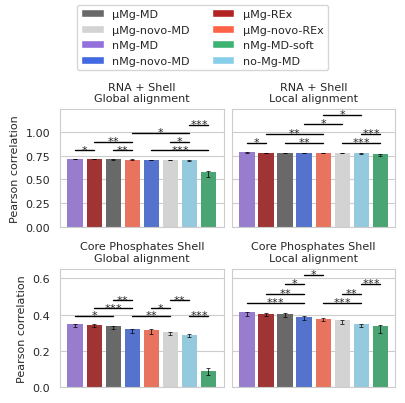

In [22]:
fig, axarr = plt.subplots(ncols=2, nrows=2, figsize=(10*cm, 10*cm), sharey='row')

toplot = [
    ('global', 'All'),
    ('local', 'All'),
    ('global', 'Core Phosphates (Shell only)'),
    ('local', 'Core Phosphates (Shell only)'),
]    

for (align, label), ax in zip(toplot, axarr.flat):

    group = res.query('mask == @label and align == @align').loc[res['sim'].isin(simselection)]
    group = group.sort_values('cc', ascending=False)
    group['sim'] = group['sim'].map(simlabels)
    group['sim'] = group['sim'].astype(CategoricalDtype(categories=group['sim'], ordered=True))

    ax = sns.barplot(
        data=group,
        y='cc',
        x='sim',
        hue='sim',
        palette=labelcolors,
        ax=ax,
        linestyle='none',
    )
    xticklabels = ax.get_xticklabels()
    ax.tick_params(axis='x', labelbottom=False)
    #for i, t in enumerate(xticklabels):
    #    ax.text(i, 0.05, t.get_text(), va='bottom', ha='center', rotation=90, transform=transforms.blended_transform_factory(ax.transData, ax.transAxes), color='white', fontsize=6, fontweight='bold')
    #ax.bar_label(ax.containers[0], label_type='center')
    
    yerr = (group['cc'] - group['cc_low'], group['cc_high'] - group['cc'])
    ax.errorbar(
        y=group['cc'],
        x=group['sim'],
        yerr=yerr,
        ls='none',
        c='black',
        capsize=1.5,
        elinewidth=0.5,
        capthick=0.5,
    )
    
    history = []
    y_max = group['cc'].max()
    h = y_max / 8

    for i, simA in enumerate(group['sim']):
        for j, simB in enumerate(group['sim']):
            if j <= i:
                continue
            significance = 0

            if p_values.loc[simB, simA, align, label] < 0.05:
                significance += 1
            if p_values.loc[simB, simA, align, label] < 0.01:
                significance += 1
            if p_values.loc[simB, simA, align, label] < 0.001:
                significance += 1

            if significance > 0:
                x1 = i
                x2 = j
                level = 1
                while True:
                    for a, b, c in history:
                        is_intersecting = x1 <= b and a <= x2
                        if level == c and is_intersecting:
                            level += 1
                            break
                    else:
                        break
                l, = ax.plot([x1, x2], [y_max + level*h, y_max + level*h], color='black', lw=1)
                t = ax.text(0.5*(x1 + x2), y_max + level*h + h/3, ''.join(significance * [r'$*$']), va='center', ha='center')
                history.append((x1, x2, level))
                break
                
    #ax.set_ylim(0, np.ceil(10*(y_max+h)) / 10)
    if label.endswith("(Shell only)"):
        label = label.removesuffix("(Shell only)") + "Shell"
    if label == 'All':
        label = 'RNA + Shell'
    ax.set_title(label + f"\n{align.capitalize()} alignment", fontsize=8)
    ax.set_xlabel(None)
for ax in axarr[:, 0]:
    ax.set_ylabel('Pearson correlation')

from matplotlib.patches import Patch
handles = [
    Patch(facecolor=labelcolors[label.get_text()]) for label in xticklabels
]
labels = [label.get_text() for label in xticklabels]

order = [labels.index(label) for label in labelselection]
labels = [labels[i] for i in order]
handles = [handles[i] for i in order]

plt.figlegend(handles, labels, loc='outside upper center', ncols=2)

fig.savefig(f'figures/cross_correlations.pdf')

In [23]:
best_tempfactors

plain_md_7ez0_mMg_tip3p        global  All                             31.9
plain_md_7ez0_nMg_tip3p        global  All                             31.4
plain_md_7ez0_nMg_tip3p_soft   global  All                             12.2
plain_md_7ez0_noion_mMg_tip3p  global  All                             32.5
plain_md_7ez0_noion_nMg_tip3p  global  All                             32.5
                                                                       ... 
plain_md_7ez0_noion_mMg_tip3p  local   Core Phosphates (Shell only)    12.5
plain_md_7ez0_noion_nMg_tip3p  local   Core Phosphates (Shell only)    12.4
plain_md_7ez0_nomg_mMg_tip3p   local   Core Phosphates (Shell only)    12.0
replex_7ez0_mMg_tip3p          local   Core Phosphates (Shell only)    12.6
replex_7ez0_noion_mMg_tip3p    local   Core Phosphates (Shell only)    12.0
Length: 96, dtype: float64

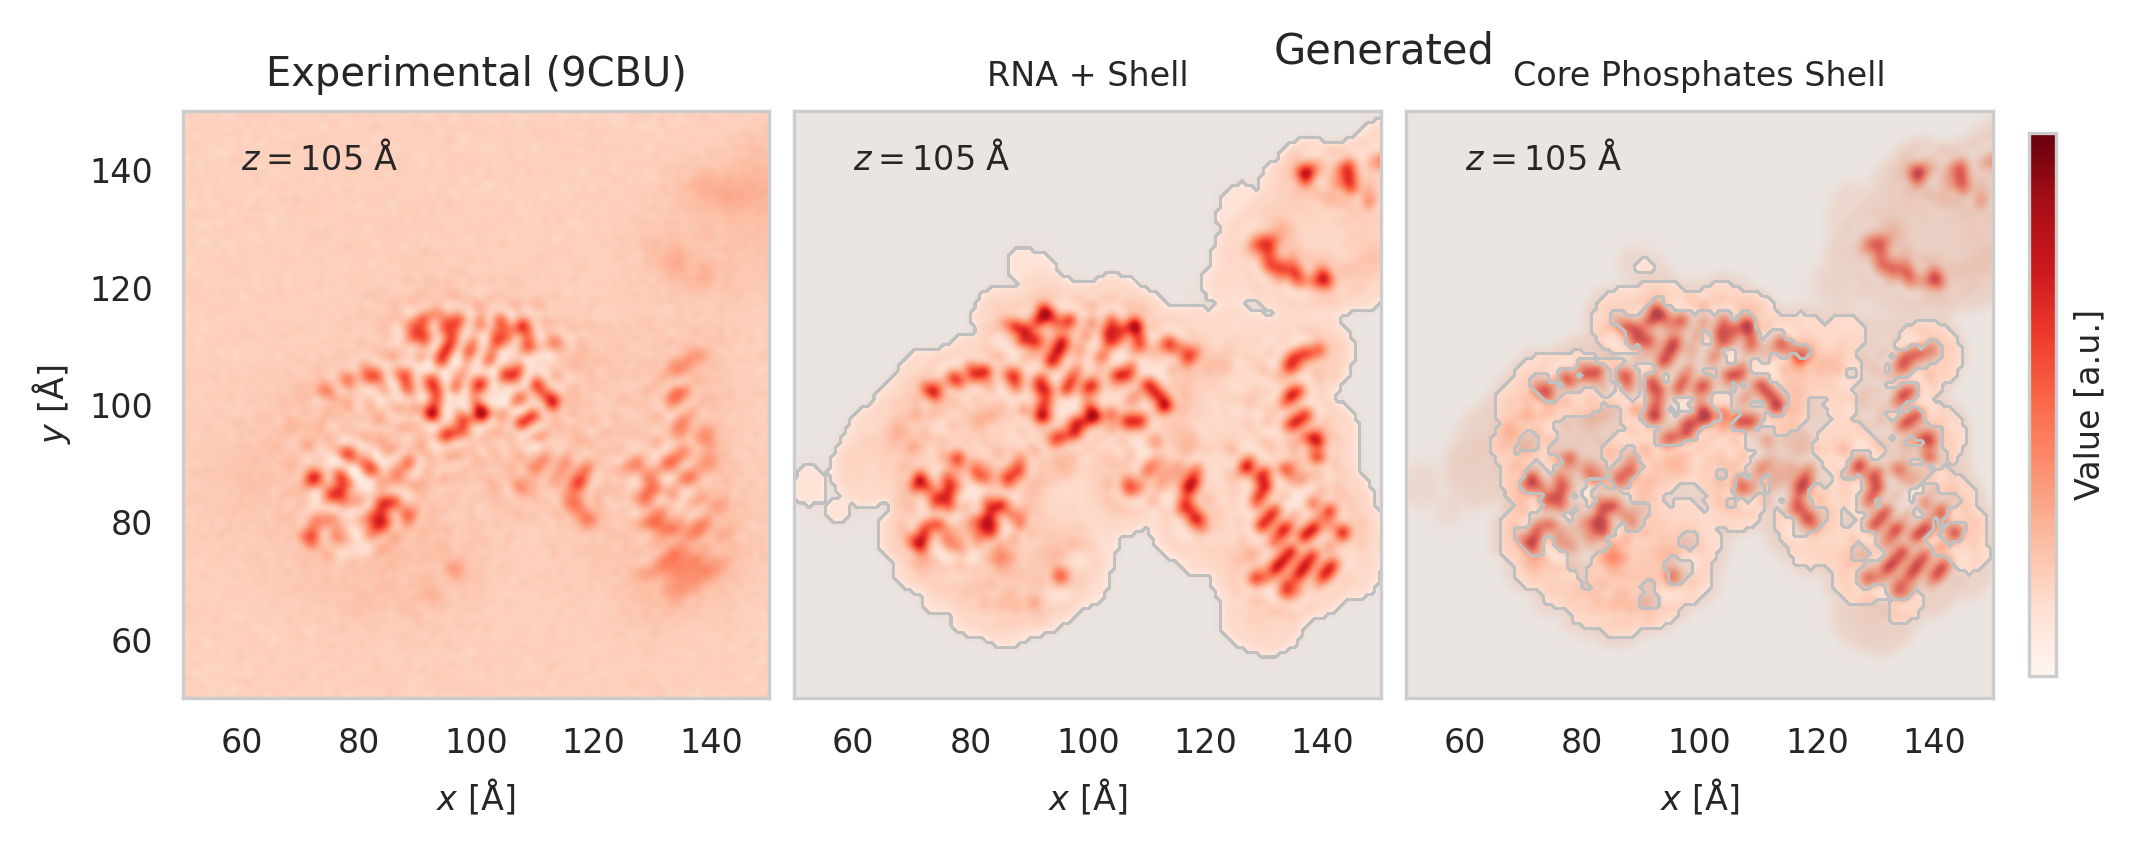

In [24]:
fig, axarr = plt.subplots(ncols=3, width_ratios=[1,1,1], figsize=(17.8*cm, 6.8*cm), dpi=300)

ref_map_ = ref_map.to_dense()

plt.rcParams['hatch.color'] = 'silver'

ax = axarr[0]
im = plot_map_slice(ref_map_, cmap='Reds', interpolation='bicubic', ax=ax)
#cbar = plt.colorbar(im, ax=ax, fraction=0.05, orientation='horizontal', location='top', label='Value [a.u.]')
ax.set_xlim(50, 150)
ax.set_ylim(50, 150)
depth = np.median(ref_map_.edges[-1])
ax.text(0.1, 0.9, f"$z = {depth:.0f}$ Å", transform=ax.transAxes)
ax.set_xlabel("$x$ [Å]")
ax.set_ylabel("$y$ [Å]")
ax.set_title('Experimental (9CBU)')
ax.grid(False)

gen_map_ = gen_map_avg.loc['replex_7ez0_mMg_tip3p', 'global'].to_dense().apply_tempfactor(best_tempfactors.loc['replex_7ez0_mMg_tip3p', 'global', 'All'])
mask = masks['All']

ax = axarr[1]
im = plot_map_slice(gen_map_, cmap='Reds', interpolation='bicubic', ax=ax)
hatches = plot_map_slice(Grid(mask, edges=gen_map_.edges), func='contourf', colors=[('silver', 0.3), 'none'], corner_mask=True, ax=ax)
hatches.set_edgecolor('silver')
hatches.set_linewidth(0.5)
#cbar = plt.colorbar(im, ax=ax, fraction=0.05, orientation='horizontal', location='top', label='Value [a.u.]')
ax.set_xlim(50, 150)
ax.set_ylim(50, 150)
depth = np.median(gen_map_.edges[-1])
ax.text(0.1, 0.9, f"$z = {depth:.0f}$ Å", transform=ax.transAxes)
ax.set_xlabel("$x$ [Å]")
ax.set_title('RNA + Shell', fontsize=8)
ax.grid(False)
ax.set_ylabel(None)
ax.tick_params(labelleft=False)

gen_map_ = gen_map_avg.loc['replex_7ez0_mMg_tip3p', 'global'].to_dense().apply_tempfactor(best_tempfactors.loc['replex_7ez0_mMg_tip3p', 'global', 'All'])
mask = masks['Core Phosphates (Shell only)']
ax = axarr[2]
im = plot_map_slice(gen_map_, cmap='Reds', interpolation='bicubic', ax=ax)
hatches = plot_map_slice(Grid(mask, edges=gen_map_.edges), func='contourf', colors=[('silver', 0.3), 'none'], corner_mask=True, ax=ax)
hatches.set_edgecolor('silver')
hatches.set_linewidth(0.5)
# cbar = plt.colorbar(im, ax=ax, fraction=0.05, orientation='horizontal', location='top', label='Value [a.u.]')
ax.set_xlim(50, 150)
ax.set_ylim(50, 150)
depth = np.median(gen_map_.edges[-1])
ax.text(0.1, 0.9, f"$z = {depth:.0f}$ Å", transform=ax.transAxes)
ax.set_xlabel("$x$ [Å]")
ax.set_title('Core Phosphates Shell', fontsize=8)
ax.grid(False)
ax.set_ylabel(None)
ax.tick_params(labelleft=False)


cbar = plt.colorbar(im, ax=axarr, fraction=0.015, label='Value [a.u.]', pad=0.02)
cbar.ax.tick_params(right=False, labelright=False)

fig.text(0.65, 1, 'Generated', ha='center', va='top', fontsize=10)


fig.savefig(f"figures/ref_gen_maps.pdf")